# Predictive Maintenance System Using Machine Learning and Flask

This project uses machine learning to predict machine failures by analyzing operating measurements such as temperature, rotational speed, torque, and tool wear.

Four machine learning models will be trained and evaluated to identify a suitable model for failure prediction. A Flask web application will allow users to enter machine measurements or upload a CSV file to obtain predictions.

The main goal is to identify potential machine failures early and support better maintenance planning.

# 1. Data Understanding and Exploratory Data Analysis (EDA)

In [1]:
# import required libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
# load dataset
df = pd.read_csv("../data/predictive_maintenance.csv")

# display
df.head()

,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


In [3]:
# check data types
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   UDI                      10000 non-null  int64  
 1   Product ID               10000 non-null  str    
 2   Type                     10000 non-null  str    
 3   Air temperature [K]      10000 non-null  float64
 4   Process temperature [K]  10000 non-null  float64
 5   Rotational speed [rpm]   10000 non-null  int64  
 6   Torque [Nm]              10000 non-null  float64
 7   Tool wear [min]          10000 non-null  int64  
 8   Machine failure          10000 non-null  int64  
 9   TWF                      10000 non-null  int64  
 10  HDF                      10000 non-null  int64  
 11  PWF                      10000 non-null  int64  
 12  OSF                      10000 non-null  int64  
 13  RNF                      10000 non-null  int64  
dtypes: float64(3), int64(9), str(2)
me

In [4]:
# check column names
df.columns.tolist()

['UDI',
 'Product ID',
 'Type',
 'Air temperature [K]',
 'Process temperature [K]',
 'Rotational speed [rpm]',
 'Torque [Nm]',
 'Tool wear [min]',
 'Machine failure',
 'TWF',
 'HDF',
 'PWF',
 'OSF',
 'RNF']

In [5]:
# check dataset columns and rows

df.shape

(10000, 14)

In [6]:
# check missing values
df.isnull().sum()

UDI                        0
Product ID                 0
Type                       0
Air temperature [K]        0
Process temperature [K]    0
Rotational speed [rpm]     0
Torque [Nm]                0
Tool wear [min]            0
Machine failure            0
TWF                        0
HDF                        0
PWF                        0
OSF                        0
RNF                        0
dtype: int64

In [7]:
# check duplicate rows  rows in dataset

df.duplicated().sum()

np.int64(0)

In [8]:
# statistical summary
df.describe()

,UDI,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
count,10000.00000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.00000
mean,5000.50000,300.004930,310.005560,1538.776100,39.986910,107.951000,0.033900,0.004600,0.011500,0.009500,0.009800,0.00190
std,2886.89568,2.000259,1.483734,179.284096,9.968934,63.654147,0.180981,0.067671,0.106625,0.097009,0.098514,0.04355
min,1.00000,295.300000,305.700000,1168.000000,3.800000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
25%,2500.75000,298.300000,308.800000,1423.000000,33.200000,53.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
50%,5000.50000,300.100000,310.100000,1503.000000,40.100000,108.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
75%,7500.25000,301.500000,311.100000,1612.000000,46.800000,162.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
max,10000.00000,304.500000,313.800000,2886.000000,76.600000,253.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.00000


In [9]:
df["Machine failure"].value_counts()

Machine failure
0    9661
1     339
Name: count, dtype: int64

In [10]:
# display failure percentage
df["Machine failure"].value_counts(normalize=True).mul(100).round(2)

Machine failure
0    96.61
1     3.39
Name: proportion, dtype: float64

# Exploratory Data Analysis

Exploratory Data Analysis (EDA) helps us understand patterns and relationships in the dataset through statistics and visualizations. 

# Machine Failure Distribution

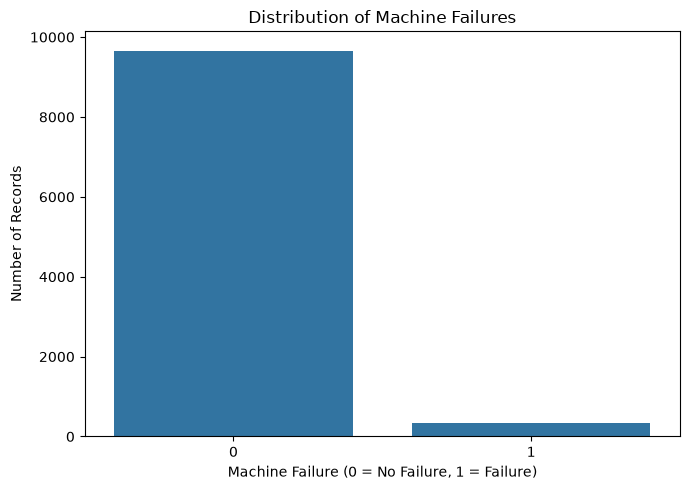

In [11]:
#visualize machine failure
plt.figure(figsize=(7, 5))
sns.countplot(data=df, x="Machine failure")
plt.title("Distribution of Machine Failures")
plt.xlabel("Machine Failure (0 = No Failure, 1 = Failure)")
plt.ylabel("Number of Records")
plt.tight_layout()
plt.savefig("../charts/machine_failure_distribution.png", dpi=300, bbox_inches="tight")

plt.show()


Machine Failure Distribution: Shows the number of machines with and without failures.

# Machine Type Distribution

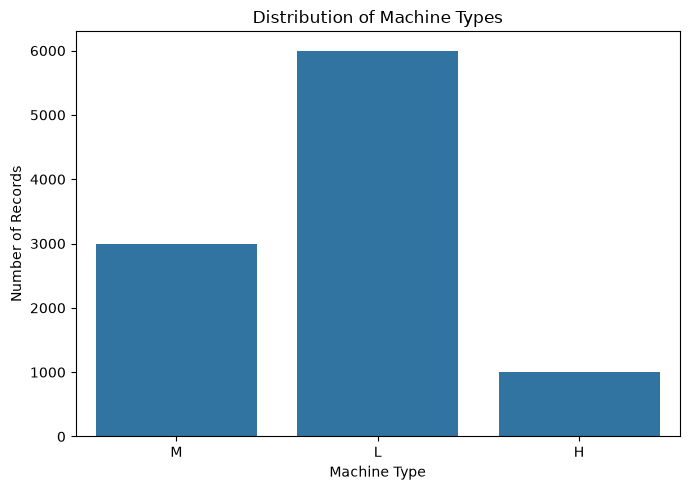

In [12]:
# Visualize machine type distribution
plt.figure(figsize=(7, 5))
sns.countplot(data=df, x="Type")

plt.title("Distribution of Machine Types")
plt.xlabel("Machine Type")
plt.ylabel("Number of Records")

plt.tight_layout()
plt.savefig("../charts/machine_type_distribution.png", dpi=300, bbox_inches="tight")

plt.show()

Machine Type Distribution: Displays the number of machines in each type category.

# Air Temperature Distribution

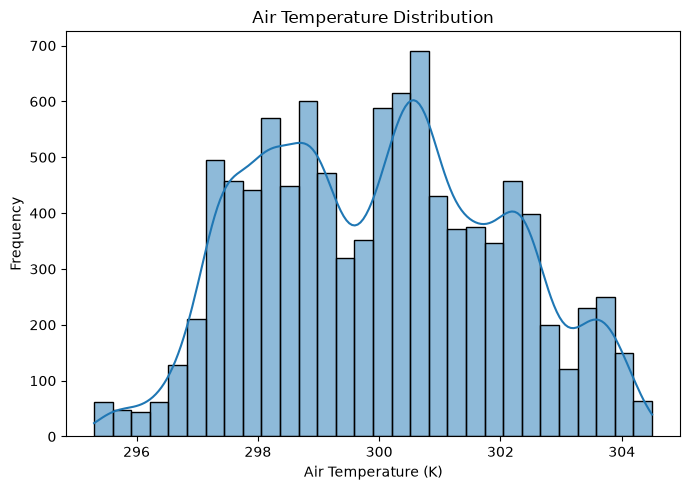

In [13]:
# Visualize air temperature distribution
plt.figure(figsize=(7, 5))
sns.histplot(data=df, x="Air temperature [K]", bins=30, kde=True)

plt.title("Air Temperature Distribution")
plt.xlabel("Air Temperature (K)")
plt.ylabel("Frequency")

plt.tight_layout()
plt.savefig("../charts/air_temperature_distribution.png", dpi=300, bbox_inches="tight")

plt.show()

Air Temperature Distribution: Shows how air temperature values are distributed.

# Correlation Heatmap

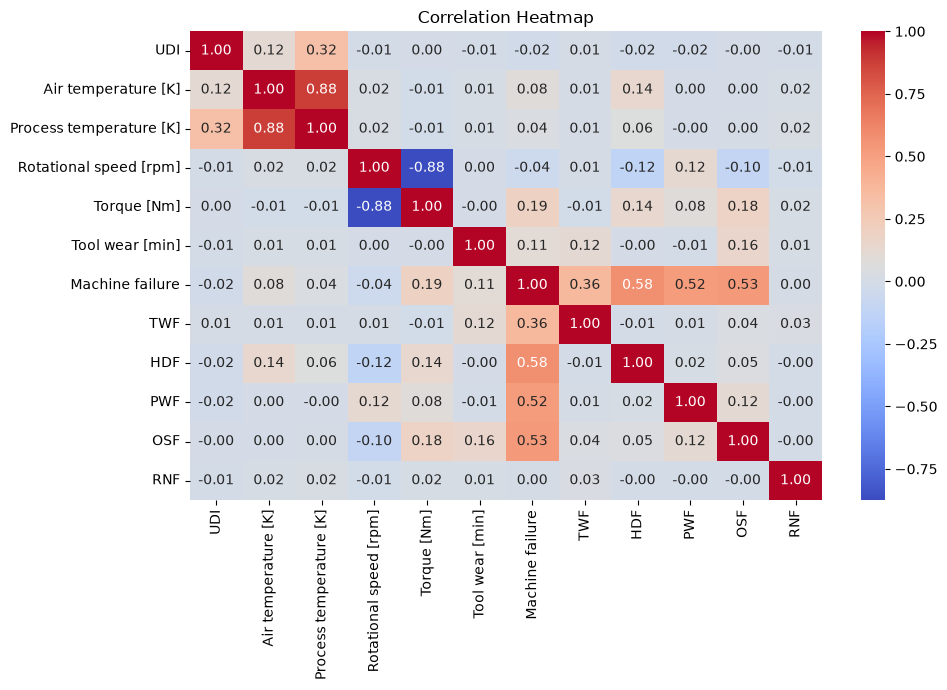

In [14]:
# Visualize correlations between numerical features

plt.figure(figsize=(10, 7))

sns.heatmap(
    df.select_dtypes(include="number").corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap")
plt.tight_layout()

plt.savefig("../charts/correlation_heatmap.png", dpi=300, bbox_inches="tight")
plt.show()

Correlation Heatmap: Highlights relationships between numerical features.

# Failure Rate by Machine Type

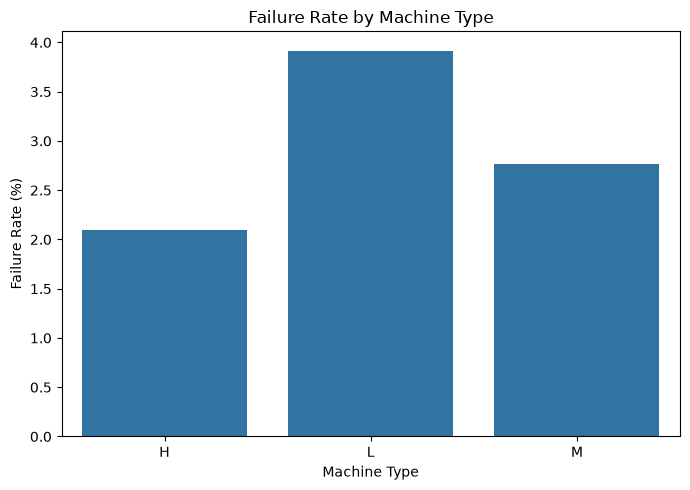

In [15]:
# Compare machine failure rates by machine type

failure_rate = df.groupby("Type")["Machine failure"].mean() * 100
plt.figure(figsize=(7, 5))

sns.barplot(x=failure_rate.index, y=failure_rate.values)
plt.title("Failure Rate by Machine Type")
plt.xlabel("Machine Type")
plt.ylabel("Failure Rate (%)")

plt.tight_layout()
plt.savefig("../charts/failure_rate_by_machine_type.png", dpi=300, bbox_inches="tight")

plt.show()

Failure Rate by Machine Type: Compares failure percentages across machine types.

# Rotational Speed vs Machine Failure

This boxplot compares rotational speed between machines with and without failures. It helps us identify differences in operating speed and potential outliers.

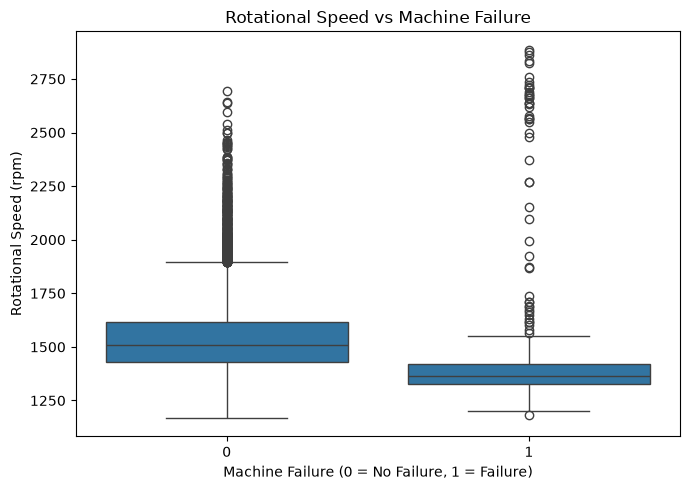

In [16]:
# Compare rotational speed by machine failure status

plt.figure(figsize=(7, 5))
sns.boxplot(data=df, x="Machine failure", y="Rotational speed [rpm]")

plt.title("Rotational Speed vs Machine Failure")
plt.xlabel("Machine Failure (0 = No Failure, 1 = Failure)")
plt.ylabel("Rotational Speed (rpm)")

plt.tight_layout()
plt.savefig("../charts/rotational_speed_vs_failure.png", dpi=300, bbox_inches="tight")
plt.show()

# Torque vs Machine Failure

This boxplot compares torque values for machines with and without failures. It helps us examine whether torque differs between the two groups.

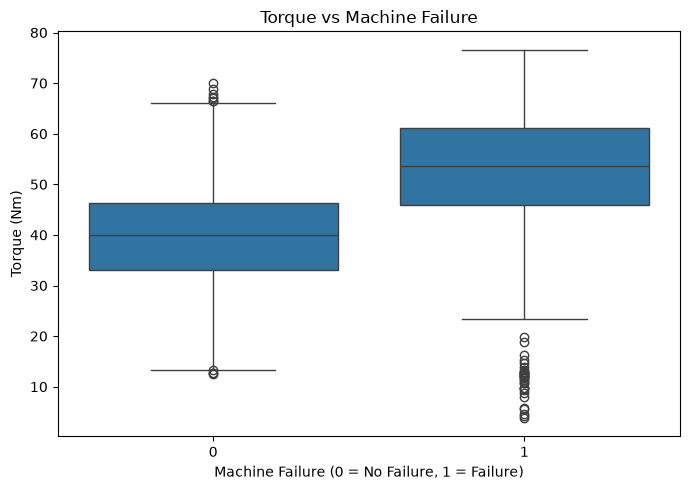

In [17]:
# Compare torque by machine failure status

plt.figure(figsize=(7, 5))
sns.boxplot(data=df, x="Machine failure", y="Torque [Nm]")

plt.title("Torque vs Machine Failure")
plt.xlabel("Machine Failure (0 = No Failure, 1 = Failure)")
plt.ylabel("Torque (Nm)")

plt.tight_layout()
plt.savefig("../charts/torque_vs_failure.png", dpi=300, bbox_inches="tight")

plt.show()

## Tool Wear vs Machine Failure

This boxplot compares tool wear between machines with and without failures. It helps us explore whether wear levels differ between the two groups.

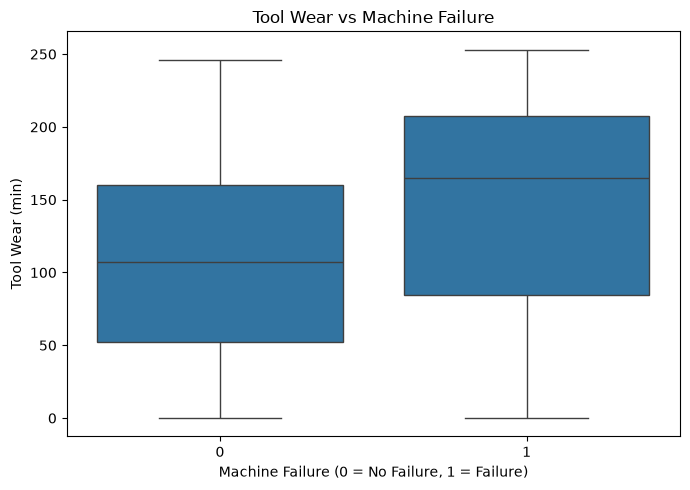

In [18]:
# Compare tool wear by machine failure status

plt.figure(figsize=(7, 5))
sns.boxplot(data=df, x="Machine failure", y="Tool wear [min]")

plt.title("Tool Wear vs Machine Failure")
plt.xlabel("Machine Failure (0 = No Failure, 1 = Failure)")
plt.ylabel("Tool Wear (min)")

plt.tight_layout()
plt.savefig("../charts/tool_wear_vs_failure.png", dpi=300, bbox_inches="tight")

plt.show()

## Key Findings from Data Visualization

The eight visualizations help us understand the dataset, machine failure distribution, machine types, and relationships between operating conditions and machine failures.

The charts examine air temperature, rotational speed, torque, and tool wear, along with correlations between numerical features.

These observations will guide the next stages of feature preparation and machine learning model development.

# Outlier Detection Using IQR

### Outlier Detection

Outliers are observations that fall unusually far from the majority of values.

The Interquartile Range (IQR) method is used to identify potential outliers in numerical sensor features.

* **Q1:** 25th percentile.
* **Q3:** 75th percentile.
* **IQR:** Q3 − Q1.
* **Lower bound:** Q1 − 1.5 × IQR.
* **Upper bound:** Q3 + 1.5 × IQR.

Values outside these bounds are flagged as potential outliers.

Outliers are not automatically removed because unusual sensor readings may represent important machine operating conditions or early signs of failure.


In [19]:
# Select numerical sensor featurs
numerical_features = [
    "Air temperature [K]",
    "Process temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]"
]

# detect potential outliers using IQR
outlier_results = []

for column in numerical_features:
    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outlier_mask = (
        (df[column] < lower_bound) |
        (df[column] > upper_bound)
    )

    outlier_count = outlier_mask.sum()

    outlier_results.append({
        "Feature": column,
        "Lower Bound": round(lower_bound, 2),
        "Upper Bound": round(upper_bound, 2),
        "Outlier Count": int(outlier_count),
        "Outlier Percentage (%)": round(
            outlier_count / len(df) * 100, 2
        )
    })

# display the results
outlier_summary = pd.DataFrame(outlier_results)

display(outlier_summary)

,Feature,Lower Bound,Upper Bound,Outlier Count,Outlier Percentage (%)
0,Air temperature [K],293.50,306.30,0,0.00
1,Process temperature [K],305.35,314.55,0,0.00
2,Rotational speed [rpm],1139.50,1895.50,418,4.18
3,Torque [Nm],12.80,67.20,69,0.69
4,Tool wear [min],-110.50,325.50,0,0.00


### Outlier Detection Findings

The IQR method was used to identify potential outliers in five numerical sensor features.

The analysis identified 418 potential outliers in rotational speed (4.18%) and 69 in torque (0.69%). No outliers were detected in air temperature, process temperature, or tool wear using this method.

These observations will be retained for further investigation because extreme sensor readings may represent meaningful machine operating conditions. Removing them without sufficient evidence could eliminate useful information for failure prediction.


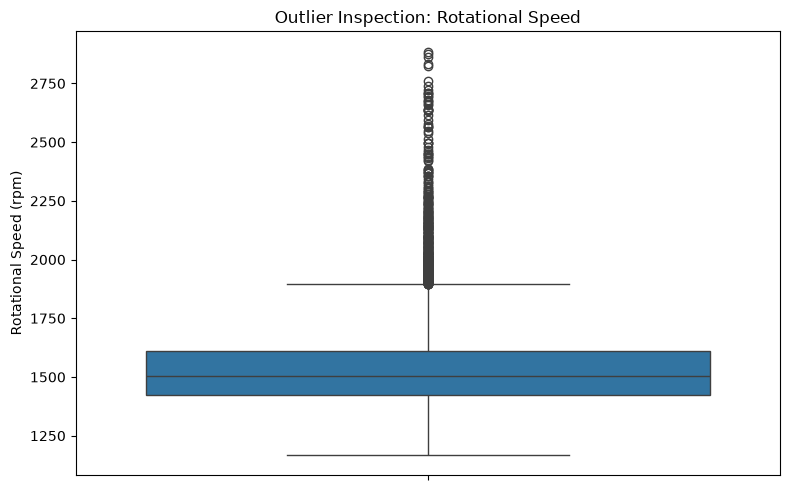

In [20]:
plt.figure(figsize=(8, 5))

sns.boxplot(data=df, y="Rotational speed [rpm]")

plt.title("Outlier Inspection: Rotational Speed")
plt.ylabel("Rotational Speed (rpm)")

plt.savefig("../charts/rotational_speed_outliers.png", dpi=300, bbox_inches="tight")
plt.tight_layout()
plt.show()

# Feature Selection

Feature selection identifies the columns used as model inputs. Failure-related columns must be checked carefully because they may reveal information about the target and lead to misleading model performance.

In [21]:
# Check failure-related columns

failure_columns = ["TWF", "HDF", "PWF", "OSF", "RNF"]
df[failure_columns + ["Machine failure"]].head()

,TWF,HDF,PWF,OSF,RNF,Machine failure
0,0,0,0,0,0,0
1,0,0,0,0,0,0
2,0,0,0,0,0,0
3,0,0,0,0,0,0
4,0,0,0,0,0,0


In [22]:
# Separate input features and target

X = df.drop(columns=["Machine failure", "TWF", "HDF", "PWF", "OSF", "RNF", "UDI", "Product ID"])
y = df["Machine failure"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)

print("\nInput features:")
print(X.columns.tolist())

Features shape: (10000, 6)
Target shape: (10000,)

Input features:
['Type', 'Air temperature [K]', 'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]']


# Encoding Categorical Features

The 'Type' column contains machine categories. One-hot encoding converts these categories into numerical columns that machine learning models can process.

In [23]:
# Convert categorical features into numerical columns

X = pd.get_dummies(X, columns=["Type"], drop_first=True, dtype=int)

print("Features shape after encoding:", X.shape)
print("\nUpdated feature columns:")

print(X.columns.tolist())

Features shape after encoding: (10000, 7)

Updated feature columns:
['Air temperature [K]', 'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]', 'Type_L', 'Type_M']


## Train-Test Split

The dataset is divided into training and testing sets. The training set is used to train the machine learning models, while the testing set evaluates their performance on unseen data.

Stratification maintains approximately the same proportion of machine failures in both sets.

In [24]:
# Split the data into training and testing sets

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.2,random_state=42,stratify=y)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (8000, 7)
Testing data: (2000, 7)


##  Data Preprocessing

Feature scaling brings numerical features onto comparable scales. The scaler is fitted on the training data and then applied to the testing data.

In [25]:
# Import preprocessing tools

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

# Selct numerical features

numerical_features = [
    "Air temperature [K]",
    "Process temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]"
]

# Scale numerical features

preprocessor = ColumnTransformer(
    transformers=[
        ("scaler", StandardScaler(), numerical_features)
    ],
    remainder="passthrough"
)

print("Preprocessing pipeline created.")

Preprocessing pipeline created.


# Machine Learning Model Development

In [26]:
# import pipeline and logisticregression

from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

In [27]:
# creating model

logistic_model = Pipeline([("preprocessor", preprocessor),("classifier", LogisticRegression(max_iter=1000, random_state=42, class_weight="balanced"))])

In [28]:
# train the model
logistic_model.fit(X_train, y_train)

print("Logistic Regression training completed.")

Logistic Regression training completed.


### Logistic Regression Evaluation

The trained Logistic Regression model is evaluated using the test dataset. Accuracy, precision, recall, F1-score, ROC-AUC, and PR-AUC are used to measure its performance.

Because machine failures are rare, recall and precision are particularly important. Recall helps us understand how many actual failures the model detects, while precision tells us how many predicted failures are correct.


In [29]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    classification_report
)

# Predict machine failures
y_pred = logistic_model.predict(X_test)
y_prob = logistic_model.predict_proba(X_test)[:, 1]

# calculate evaluation metrics
print("Accuracy:", round(accuracy_score(y_test, y_pred), 4))
print("Precision:", round(precision_score(y_test, y_pred, zero_division=0), 4))
print("Recall:", round(recall_score(y_test, y_pred, zero_division=0), 4))
print("F1-score:", round(f1_score(y_test, y_pred, zero_division=0), 4))
print("ROC-AUC:", round(roc_auc_score(y_test, y_prob), 4))
print("PR-AUC:", round(average_precision_score(y_test, y_prob), 4))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))

Accuracy: 0.8245
Precision: 0.1418
Recall: 0.8235
F1-score: 0.2419
ROC-AUC: 0.9069
PR-AUC: 0.3817

Confusion Matrix:
[[1593  339]
 [  12   56]]

Classification Report:
              precision    recall  f1-score   support

           0       0.99      0.82      0.90      1932
           1       0.14      0.82      0.24        68

    accuracy                           0.82      2000
   macro avg       0.57      0.82      0.57      2000
weighted avg       0.96      0.82      0.88      2000



# Decision Tree Classifier

A Decision Tree Classifier predicts machine failures by learning decision rules from the sensor data. It can capture nonlinear relationships and is relatively easy to interpret.

The model will be trained using the same training data and evaluated on the same test data so that its performance can be compared fairly with Logistic Regression.


In [30]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.pipeline import Pipeline

# create the Decision Tree model
decision_tree_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", DecisionTreeClassifier(
        random_state=42,
        class_weight="balanced"
    ))
])

# train the model
decision_tree_model.fit(X_train, y_train)

print("Decision Tree training completed.")

Decision Tree training completed.


### Decision Tree Evaluation

The Decision Tree model is evaluated using the test dataset. Accuracy, precision, recall, F1-score, ROC-AUC, and PR-AUC are calculated to assess its performance.

The results will be compared with Logistic Regression to determine which model better identifies machine failures while minimizing missed failures and unnecessary maintenance alerts.


In [31]:
# Predict machine failures
dt_pred = decision_tree_model.predict(X_test)
dt_prob = decision_tree_model.predict_proba(X_test)[:, 1]

# Calculate evaluation metrics
print("Decision Tree Evaluation")
print("-" * 30)

print("Accuracy:", round(accuracy_score(y_test, dt_pred), 4))
print("Precision:", round(precision_score(y_test, dt_pred, zero_division=0), 4))
print("Recall:", round(recall_score(y_test, dt_pred, zero_division=0), 4))
print("F1-score:", round(f1_score(y_test, dt_pred, zero_division=0), 4))
print("ROC-AUC:", round(roc_auc_score(y_test, dt_prob), 4))
print("PR-AUC:", round(average_precision_score(y_test, dt_prob), 4))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, dt_pred))

print("\nClassification Report:")
print(classification_report(y_test, dt_pred, zero_division=0))

Decision Tree Evaluation
------------------------------
Accuracy: 0.978
Precision: 0.7
Recall: 0.6176
F1-score: 0.6562
ROC-AUC: 0.8042
PR-AUC: 0.4454

Confusion Matrix:
[[1914   18]
 [  26   42]]

Classification Report:
              precision    recall  f1-score   support

           0       0.99      0.99      0.99      1932
           1       0.70      0.62      0.66        68

    accuracy                           0.98      2000
   macro avg       0.84      0.80      0.82      2000
weighted avg       0.98      0.98      0.98      2000



### Random Forest Classifier

Random Forest is an ensemble learning algorithm that combines predictions from multiple decision trees. It can capture complex relationships in sensor data and may improve predictive performance compared with a single decision tree.

The model will be trained using the same training dataset and evaluated on the same test dataset for a fair comparison with the previous models.


In [32]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline

# Create the Random Forest model
random_forest_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=100,
        random_state=42,
        class_weight="balanced",
        n_jobs=-1
    ))
])

# Train the model
random_forest_model.fit(X_train, y_train)

print("Random Forest training completed.")

Random Forest training completed.


### Random Forest Evaluation

The Random Forest model is evaluated using the test dataset. Accuracy, precision, recall, F1-score, ROC-AUC, and PR-AUC are calculated to assess its predictive performance.

Since machine failures are rare, particular attention is given to recall, precision, and the confusion matrix. The results will be compared with Logistic Regression and Decision Tree to identify a suitable model for predictive maintenance.


In [33]:
# Predict machine failures
rf_pred = random_forest_model.predict(X_test)
rf_prob = random_forest_model.predict_proba(X_test)[:, 1]

# Calculate evaluation metrics
print("Random Forest Evaluation")
print("-" * 30)

print("Accuracy:", round(accuracy_score(y_test, rf_pred), 4))
print("Precision:", round(precision_score(y_test, rf_pred, zero_division=0), 4))
print("Recall:", round(recall_score(y_test, rf_pred, zero_division=0), 4))
print("F1-score:", round(f1_score(y_test, rf_pred, zero_division=0), 4))
print("ROC-AUC:", round(roc_auc_score(y_test, rf_prob), 4))
print("PR-AUC:", round(average_precision_score(y_test, rf_prob), 4))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, rf_pred))

print("\nClassification Report:")
print(classification_report(y_test, rf_pred, zero_division=0))

Random Forest Evaluation
------------------------------
Accuracy: 0.981
Precision: 0.7344
Recall: 0.6912
F1-score: 0.7121
ROC-AUC: 0.9597
PR-AUC: 0.7814

Confusion Matrix:
[[1915   17]
 [  21   47]]

Classification Report:
              precision    recall  f1-score   support

           0       0.99      0.99      0.99      1932
           1       0.73      0.69      0.71        68

    accuracy                           0.98      2000
   macro avg       0.86      0.84      0.85      2000
weighted avg       0.98      0.98      0.98      2000



### Artificial Neural Network (ANN)

An Artificial Neural Network is a machine learning model that learns patterns from input features through interconnected layers.

In this project, the ANN will use machine sensor readings to predict machine failures. Its performance will be evaluated using the same metrics as the previous models.


In [34]:
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import Pipeline

# Create the ANN model
ann_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", MLPClassifier(
        hidden_layer_sizes=(64, 32),
        activation="relu",
        max_iter=300,
        early_stopping=True,
        random_state=42
    ))
])

# Train the model
ann_model.fit(X_train, y_train)

print("ANN training completed.")

ANN training completed.


### Artificial Neural Network Evaluation

The ANN model is evaluated using the test dataset. Accuracy, precision, recall, F1-score, ROC-AUC, and PR-AUC are calculated to assess its performance.

The results will be compared with the other models to identify a suitable model for predicting machine failures.


In [35]:
# Predict machine failures
ann_pred = ann_model.predict(X_test)
ann_prob = ann_model.predict_proba(X_test)[:, 1]

# Calculate evaluation metrics
print("ANN Evaluation")
print("-" * 30)

print("Accuracy:", round(accuracy_score(y_test, ann_pred), 4))
print("Precision:", round(precision_score(y_test, ann_pred, zero_division=0), 4))
print("Recall:", round(recall_score(y_test, ann_pred, zero_division=0), 4))
print("F1-score:", round(f1_score(y_test, ann_pred, zero_division=0), 4))
print("ROC-AUC:", round(roc_auc_score(y_test, ann_prob), 4))
print("PR-AUC:", round(average_precision_score(y_test, ann_prob), 4))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, ann_pred))

print("\nClassification Report:")
print(classification_report(y_test, ann_pred, zero_division=0))

ANN Evaluation
------------------------------
Accuracy: 0.974
Precision: 0.7353
Recall: 0.3676
F1-score: 0.4902
ROC-AUC: 0.9435
PR-AUC: 0.5528

Confusion Matrix:
[[1923    9]
 [  43   25]]

Classification Report:
              precision    recall  f1-score   support

           0       0.98      1.00      0.99      1932
           1       0.74      0.37      0.49        68

    accuracy                           0.97      2000
   macro avg       0.86      0.68      0.74      2000
weighted avg       0.97      0.97      0.97      2000



### Model Performance Comparison

The four classification models were evaluated using accuracy, precision, recall, F1-score, ROC-AUC, and PR-AUC. Random Forest achieved the strongest overall results across most metrics, while Logistic Regression achieved the highest recall.

The final model selection will consider both predictive performance and the business cost of missed machine failures and false alarms.


In [36]:
import pandas as pd

comparison_df = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Decision Tree",
        "Random Forest",
        "ANN"
    ],
    "Accuracy": [0.8245, 0.9780, 0.9810, 0.9740],
    "Precision": [0.1418, 0.7000, 0.7344, 0.7353],
    "Recall": [0.8235, 0.6176, 0.6912, 0.3676],
    "F1-score": [0.2419, 0.6562, 0.7121, 0.4902],
    "ROC-AUC": [0.9069, 0.8042, 0.9597, 0.9435],
    "PR-AUC": [0.3817, 0.4454, 0.7814, 0.5528]
})

comparison_df

,Model,Accuracy,Precision,Recall,F1-score,ROC-AUC,PR-AUC
0,Logistic Regression,0.8245,0.1418,0.8235,0.2419,0.9069,0.3817
1,Decision Tree,0.9780,0.7000,0.6176,0.6562,0.8042,0.4454
2,Random Forest,0.9810,0.7344,0.6912,0.7121,0.9597,0.7814
3,ANN,0.9740,0.7353,0.3676,0.4902,0.9435,0.5528


### Feature Importance Analysis

Feature importance is used to identify which sensor measurements contribute most to the Random Forest model's predictions.

Understanding these features helps identify the factors associated with machine failure and supports informed predictive maintenance decisions.


                   Feature  Importance
3              Torque [Nm]    0.324785
2   Rotational speed [rpm]    0.283552
4          Tool wear [min]    0.214098
0      Air temperature [K]    0.097304
1  Process temperature [K]    0.065023
5                   Type_L    0.008782
6                   Type_M    0.006457


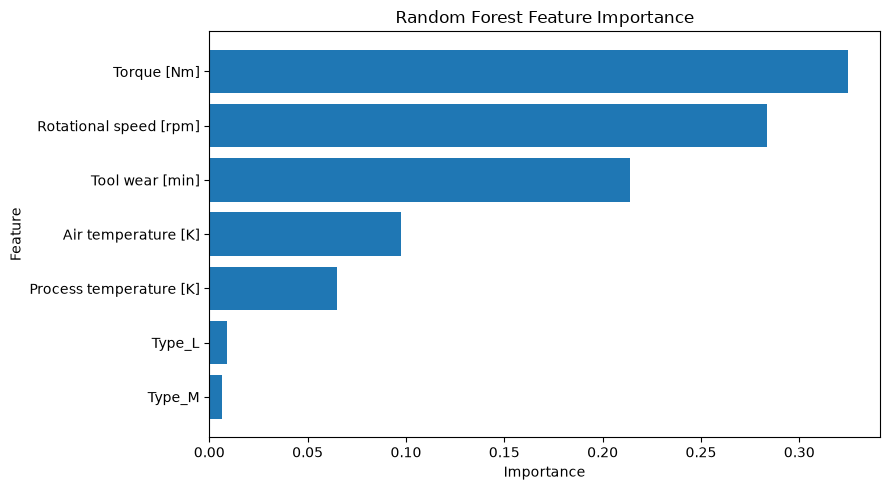

In [37]:
# Get the trained Random Forest model
rf_classifier = random_forest_model.named_steps["classifier"]

# Get feature importance values
feature_importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": rf_classifier.feature_importances_
})

# Sort features by importance
feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

# Display feature importance
print(feature_importance)

# Plot feature importance
plt.figure(figsize=(9, 5))
plt.barh(
    feature_importance["Feature"],
    feature_importance["Importance"]
)
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.title("Random Forest Feature Importance")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.savefig("../charts/random_forest_feature_importance.png", dpi=300)
plt.show()

### Feature Importance Findings

The Random Forest feature importance analysis identified torque, rotational speed, and tool wear as the three most important features for predicting machine failure. Together, these features account for approximately 82.25% of the model's total feature importance.

Air temperature and process temperature contribute less to the model's predictions, while machine type has relatively low importance.

These findings suggest that torque, rotational speed, and tool wear deserve particular attention when monitoring machine condition. However, feature importance indicates how the model uses the available features; it does not establish a direct causal relationship with machine failure.


### Random Forest Hyperparameter Tuning

Hyperparameter tuning is used to identify suitable settings for a machine learning model. GridSearchCV evaluates different combinations of hyperparameters using cross-validation.

For this project, Random Forest will be tuned using five-fold cross-validation, with F1-score as the selection metric. This helps balance the detection of actual machine failures against false alarms.


In [38]:
from sklearn.model_selection import GridSearchCV

# define the parameters to test
param_grid = {
    "classifier__n_estimators": [100, 200],
    "classifier__max_depth": [None, 10, 20],
    "classifier__min_samples_split": [2, 5],
    "classifier__min_samples_leaf": [1, 2]
}

# Create the grid search
rf_grid_search = GridSearchCV(
    estimator=random_forest_model,
    param_grid=param_grid,
    scoring="f1",
    cv=5,
    n_jobs=-1,
    verbose=1
)

# train and compare parameter combinations
rf_grid_search.fit(X_train, y_train)

# Display the best parameters and score
print("Best Parameters:")
print(rf_grid_search.best_params_)

print("\nBest Cross-Validation F1-Score:")
print(round(rf_grid_search.best_score_, 4))

Fitting 5 folds for each of 24 candidates, totalling 120 fits
Best Parameters:
{'classifier__max_depth': None, 'classifier__min_samples_leaf': 1, 'classifier__min_samples_split': 2, 'classifier__n_estimators': 200}

Best Cross-Validation F1-Score:
0.6973


### Random Forest Hyperparameter Tuning Results

GridSearchCV was used to evaluate 24 Random Forest hyperparameter combinations using five-fold cross-validation.

The best configuration used 200 trees, no specified maximum tree depth, a minimum of two samples required to split a node, and a minimum of one sample per leaf.

The best cross-validation F1-score was 0.6973. The selected configuration will now be evaluated on the independent test set to assess its performance on unseen data.


In [39]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    classification_report
)

# Get the best tuned model
best_rf_model = rf_grid_search.best_estimator_

# Predict on the test set
y_pred_tuned = best_rf_model.predict(X_test)
y_prob_tuned = best_rf_model.predict_proba(X_test)[:, 1]

# Calculate evaluation metrics
print("Tuned Random Forest Evaluation")
print("-" * 35)
print("Accuracy:", round(accuracy_score(y_test, y_pred_tuned), 4))
print("Precision:", round(precision_score(y_test, y_pred_tuned, zero_division=0), 4))
print("Recall:", round(recall_score(y_test, y_pred_tuned, zero_division=0), 4))
print("F1-Score:", round(f1_score(y_test, y_pred_tuned, zero_division=0), 4))
print("ROC-AUC:", round(roc_auc_score(y_test, y_prob_tuned), 4))
print("PR-AUC:", round(average_precision_score(y_test, y_prob_tuned), 4))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_tuned))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_tuned, zero_division=0))

Tuned Random Forest Evaluation
-----------------------------------
Accuracy: 0.982
Precision: 0.75
Recall: 0.7059
F1-Score: 0.7273
ROC-AUC: 0.9638
PR-AUC: 0.7868

Confusion Matrix:
[[1916   16]
 [  20   48]]

Classification Report:
              precision    recall  f1-score   support

           0       0.99      0.99      0.99      1932
           1       0.75      0.71      0.73        68

    accuracy                           0.98      2000
   macro avg       0.87      0.85      0.86      2000
weighted avg       0.98      0.98      0.98      2000



### Tuned Random Forest Evaluation Findings

The tuned Random Forest achieved 98.20% accuracy, 75.00% precision, 70.59% recall, and a 72.73% F1-score.

It detected 48 of 68 actual failures, missed 20, and generated 16 false alarms. Overall, tuning improved all six evaluation metrics, making this model a strong candidate for the final system.


### Final Model Selection

The tuned Random Forest model is selected as the leading candidate because it achieved 98.20% accuracy, 72.73% F1-score, and 78.68% PR-AUC. Its performance will be considered alongside failure detection and false alarm rates to determine its suitability for predictive maintenance.


In [40]:
import joblib
import os

# creat the models folder if needed
os.makedirs("../models", exist_ok=True)

# save tuned model
joblib.dump(best_rf_model, "../models/best_model.pkl")

print("Tuned model saved successfully!")

Tuned model saved successfully!


In [41]:
model_path = "../models/best_model.pkl"

if os.path.exists(model_path):
    print("Model file exists.")
    print("File size:", round(os.path.getsize(model_path) / 1024, 2), "KB")
else:
    print("Model file not found. Check the save path.")

Model file exists.
File size: 6897.14 KB
